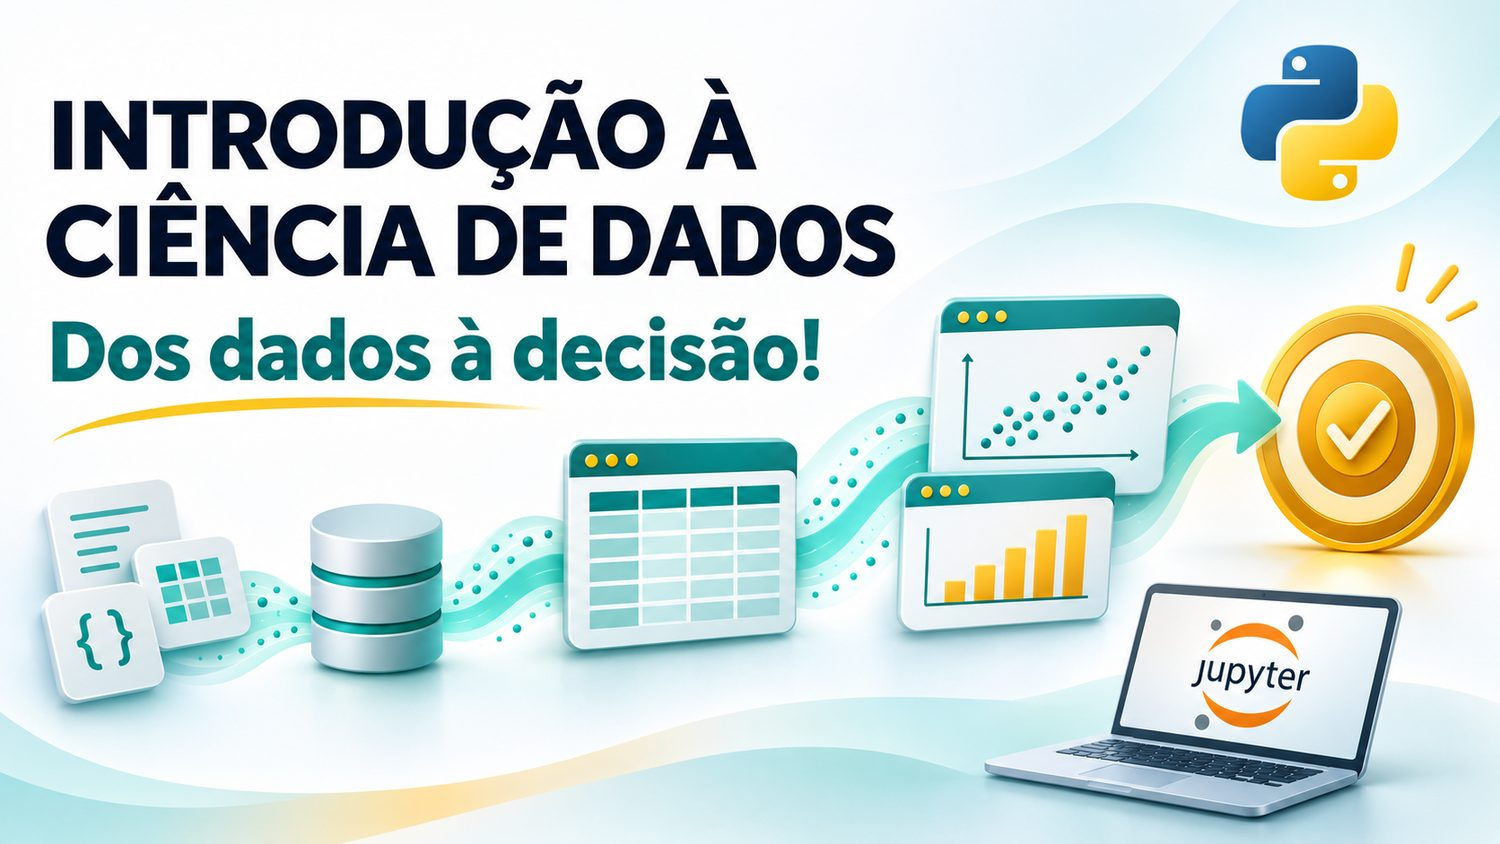

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_1_do_problema_a_decisao/05_Projeto_Enquadrar_um_Problema.ipynb)

# Capítulo 5 – Projeto: enquadrar um problema

Este capítulo é um exercício de papel e lápis feito num notebook. Não há dados para analisar nem modelos para treinar: o trabalho é transformar um desafio do mundo real numa pergunta analítica que se consiga defender e que apoie uma decisão. É a fase mais barata de um projeto e a que mais erros evita.

> **Objetivos:** aplicar os capítulos 1 a 4 a um problema novo; preencher uma ficha de enquadramento com oito componentes; antecipar objeções ao enquadramento; reconhecer que o mesmo problema admite enquadramentos diferentes.

**Pré-requisitos:** capítulos 1 a 4.

**Duração sugerida:** 60 minutos, a solo ou em grupos de três ou quatro pessoas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

## A ficha de enquadramento

A ficha tem oito componentes. Os quatro primeiros definem **o que se quer**; os quatro últimos definem **como se vai saber**.

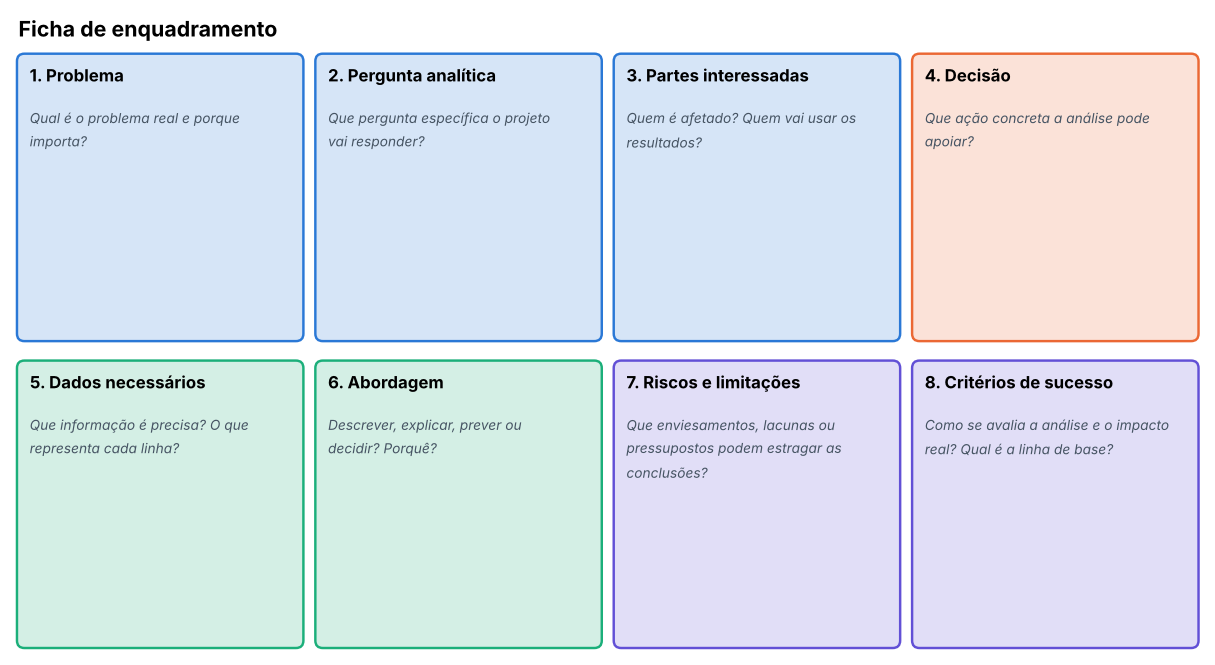

In [2]:
import textwrap

COMPONENTES = [
    ("1. Problema", "Qual é o problema real e porque importa?", AZUL),
    ("2. Pergunta analítica", "Que pergunta específica o projeto vai responder?", AZUL),
    ("3. Partes interessadas", "Quem é afetado? Quem vai usar os resultados?", AZUL),
    ("4. Decisão", "Que ação concreta a análise pode apoiar?", LARANJA),
    ("5. Dados necessários", "Que informação é precisa? O que representa cada linha?", VERDE),
    ("6. Abordagem", "Descrever, explicar, prever ou decidir? Porquê?", VERDE),
    ("7. Riscos e limitações", "Que enviesamentos, lacunas ou pressupostos podem estragar as conclusões?", VIOLETA),
    ("8. Critérios de sucesso", "Como se avalia a análise e o impacto real? Qual é a linha de base?", VIOLETA),
]


def desenhar_ficha(respostas=None, titulo="Ficha de enquadramento"):
    """Desenha a ficha. `respostas` é um dicionário {número do componente: texto}."""
    respostas = respostas or {}
    fig, ax = tela(16, 8.6, (14, 7.6))
    ax.text(0.1, 8.25, titulo, fontsize=14, fontweight="bold")
    for i, (nome, pergunta, cor) in enumerate(COMPONENTES):
        x, y = 0.1 + (i % 4) * 4.0, 4.2 - (i // 4) * 4.1
        caixa(ax, x, y, 3.8, 3.8, "", cor)
        ax.text(x + 0.15, y + 3.45, nome, fontweight="bold", fontsize=11)
        if i + 1 in respostas:
            texto = textwrap.fill(respostas[i + 1], 37)
            ax.text(x + 0.15, y + 3.1, texto, fontsize=8.6, va="top", linespacing=1.4)
        else:
            ax.text(x + 0.15, y + 3.1, textwrap.fill(pergunta, 36), fontsize=9, va="top", color="#465463", style="italic", linespacing=1.4)
    plt.show()


desenhar_ficha()

Duas notas sobre os componentes menos óbvios:

- **Unidade de análise** (componente 5): é aquilo que cada linha da tabela representa. No caso da clínica, uma linha era uma *marcação*, não um paciente. A escolha muda tudo: com uma linha por paciente responder-se-ia a «quem costuma faltar?»; com uma linha por marcação responde-se a «esta consulta vai ficar vazia?».
- **Linha de base** (componente 8): é aquilo com que o resultado se compara. Normalmente é a prática atual. Sem linha de base não há forma de dizer se o projeto melhorou alguma coisa.

## Exemplo resolvido: as faltas a consultas

A ficha seguinte resume o caso que acompanhámos nos capítulos anteriores.

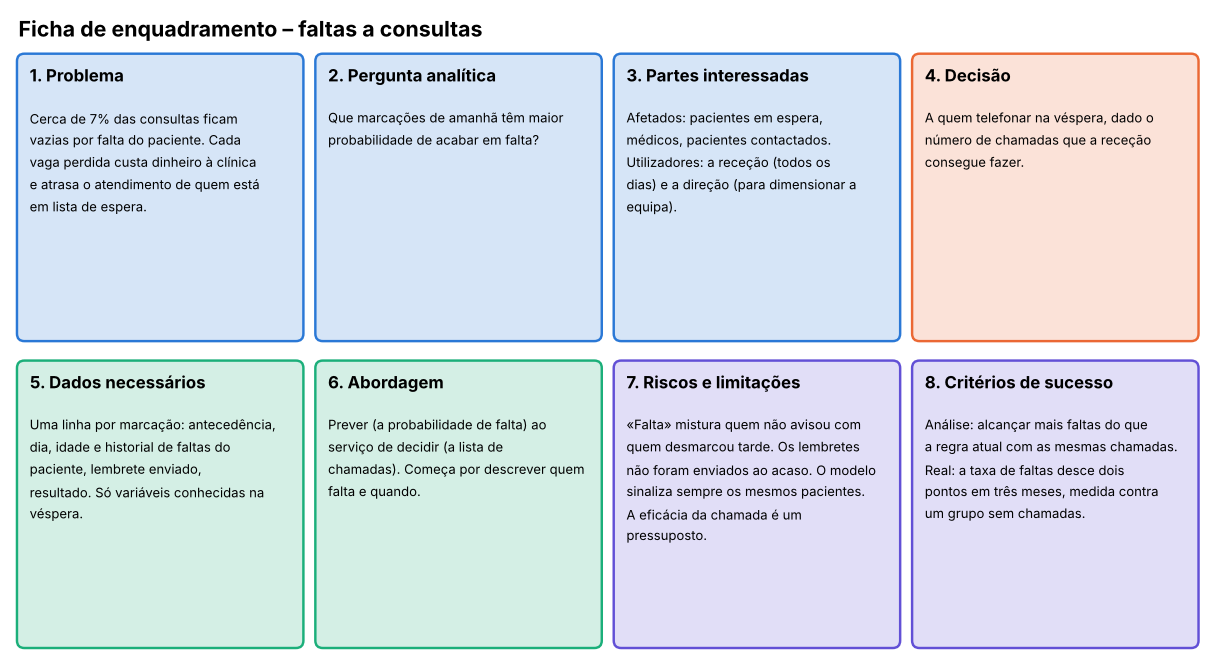

In [3]:
clinica = {
    1: "Cerca de 7% das consultas ficam vazias por falta do paciente. Cada vaga perdida custa dinheiro à clínica "
       "e atrasa o atendimento de quem está em lista de espera.",
    2: "Que marcações de amanhã têm maior probabilidade de acabar em falta?",
    3: "Afetados: pacientes em espera, médicos, pacientes contactados. Utilizadores: a receção (todos os dias) "
       "e a direção (para dimensionar a equipa).",
    4: "A quem telefonar na véspera, dado o número de chamadas que a receção consegue fazer.",
    5: "Uma linha por marcação: antecedência, dia, idade e historial de faltas do paciente, lembrete enviado, "
       "resultado. Só variáveis conhecidas na véspera.",
    6: "Prever (a probabilidade de falta) ao serviço de decidir (a lista de chamadas). Começa por descrever "
       "quem falta e quando.",
    7: "«Falta» mistura quem não avisou com quem desmarcou tarde. Os lembretes não foram enviados ao acaso. "
       "O modelo sinaliza sempre os mesmos pacientes. A eficácia da chamada é um pressuposto.",
    8: "Análise: alcançar mais faltas do que a regra atual com as mesmas chamadas. Real: a taxa de faltas desce "
       "dois pontos em três meses, medida contra um grupo sem chamadas.",
}
desenhar_ficha(clinica, "Ficha de enquadramento – faltas a consultas")

## Escolhe um cenário

Escolhe **um** dos três cenários. Em grupo, é interessante que dois grupos trabalhem o mesmo cenário sem falarem entre si: no fim comparam-se as fichas.

### Cenário A – Perdas de água

Uma empresa municipal perde um quarto da água que trata antes de ela chegar às torneiras, em fugas e ruturas na rede. Quer reduzir as perdas sem aumentar o orçamento de manutenção.

- **Informação disponível:** caudais medidos à entrada de cada zona da rede, consumos faturados, idade e material das condutas, histórico de ruturas reparadas.
- **Desafio:** que análise ajudaria a decidir onde inspecionar e que condutas substituir primeiro?
- **Para pensar:** a unidade de análise é a conduta, a zona ou a rua? As ruturas registadas são todas as que existiram? Água não faturada é o mesmo que água perdida?

### Cenário B – Livros esgotados

Uma cadeia de vinte livrarias tem, ao mesmo tempo, títulos esgotados em algumas lojas e parados em armazém noutras. Quer menos vendas perdidas sem aumentar o stock total.

- **Informação disponível:** vendas por título, loja e dia; stock no fim de cada dia; encomendas a editoras; calendário de lançamentos e de feiras do livro.
- **Desafio:** que análise ajudaria a decidir quantos exemplares de cada título enviar para cada loja?
- **Para pensar:** como se mede uma venda que não aconteceu porque o livro estava esgotado? Faz sentido prever título a título, ou por género? O que acontece com um título acabado de lançar, sem histórico?

### Cenário C – Bicicletas partilhadas

Uma cidade tem um sistema de bicicletas partilhadas com 120 estações. De manhã, as estações das zonas altas ficam vazias e as do centro ficam cheias, sem lugares para devolver. Há três carrinhas para redistribuir bicicletas.

- **Informação disponível:** registo de cada viagem (estação e hora de partida e de chegada), ocupação de cada estação de dez em dez minutos, meteorologia, relevo.
- **Desafio:** que análise ajudaria a planear as rotas das carrinhas?
- **Para pensar:** a unidade de análise é a viagem, a estação ou a estação em cada meia hora? As viagens registadas mostram a procura real? Quem ganha e quem perde se as carrinhas servirem primeiro as estações mais movimentadas?

## Parte 1 – Do problema à pergunta (10 minutos)

Para o teu cenário, escreve três perguntas, uma de cada tipo:

1. uma pergunta **descritiva**: o que gostavas de perceber sobre a situação atual?
2. uma pergunta **preditiva**: que resultado futuro ou desconhecido podias tentar estimar?
3. uma pergunta **de decisão**: que decisão ficaria mais bem informada?

Depois escolhe a mais útil e justifica: porque importa e quem usaria a resposta.

In [4]:
perguntas = {
    "descritiva": "...",
    "preditiva": "...",
    "de decisão": "...",
    "escolhida e porquê": "...",
}
for tipo, texto in perguntas.items():
    print(f"{tipo.upper()}: {texto}")

DESCRITIVA: ...
PREDITIVA: ...
DE DECISÃO: ...
ESCOLHIDA E PORQUÊ: ...


## Parte 2 – A ficha (25 minutos)

Preenche o dicionário abaixo e executa a célula para ver a tua ficha. Escreve frases curtas: a ficha tem de caber numa página.

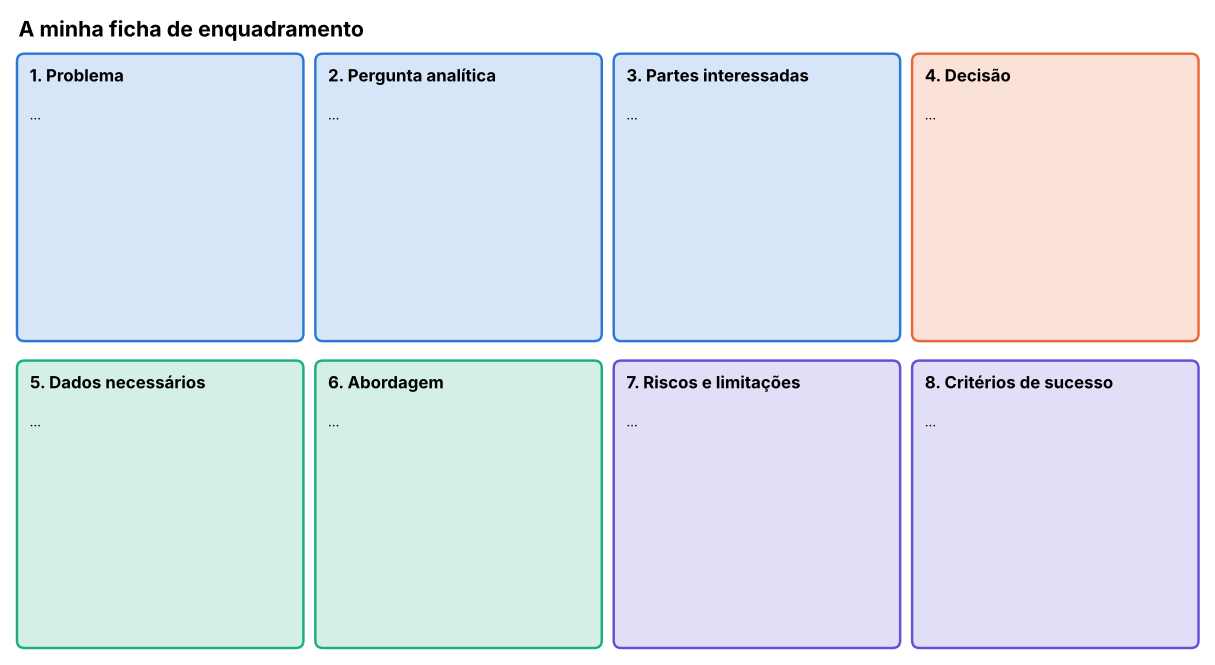

In [5]:
a_minha_ficha = {
    1: "...",   # Problema
    2: "...",   # Pergunta analítica
    3: "...",   # Partes interessadas
    4: "...",   # Decisão
    5: "...",   # Dados necessários (e unidade de análise)
    6: "...",   # Abordagem
    7: "...",   # Riscos e limitações
    8: "...",   # Critérios de sucesso (e linha de base)
}
desenhar_ficha(a_minha_ficha, "A minha ficha de enquadramento")

## Parte 3 – Apresentar e defender (25 minutos)

Um enquadramento só fica sólido depois de alguém tentar deitá-lo abaixo.

- **Apresentar (2 minutos):** o problema, a pergunta, os dados necessários e a decisão.
- **Responder a objeções (1 minuto):** quem ouve põe em causa os pressupostos, a viabilidade e as consequências de um erro.
- **Comparar:** se dois grupos trabalharam o mesmo cenário, enquadraram o mesmo problema? Quase nunca. Vale a pena perceber porquê.

Se estiveres a trabalhar sozinho, responde por escrito a estas cinco objeções:

1. Se a previsão fosse perfeita, o que farias de diferente amanhã? (Se a resposta for «nada», a pergunta está mal escolhida.)
2. Que variável da tua lista só se conhece depois do facto?
3. Quem não aparece nos teus dados?
4. Qual dos dois erros (falso alarme ou caso não detetado) custa mais, e a quem?
5. Com que comparas o teu resultado?

### Reflexão final

Escreve duas ou três frases sobre a afirmação seguinte, com um exemplo do teu cenário:

> «Uma previsão tecnicamente correta não leva necessariamente a uma boa decisão.»

## Grelha de autoavaliação

| Critério | Insuficiente | Bom |
| --- | --- | --- |
| Problema | Descreve os dados («temos registos de…») | Descreve uma consequência real, para alguém |
| Pergunta | Vaga ou impossível de responder com dados | Específica, com unidade de análise e horizonte temporal |
| Decisão | «Melhorar», «otimizar» | Uma ação, com quem a executa e quando |
| Dados | Lista tudo o que existe | Só o que se conhece no momento da decisão; identifica o que falta |
| Riscos | Genéricos («os dados podem ter erros») | Específicos do cenário, com o efeito que teriam na conclusão |
| Sucesso | Só uma métrica de modelo | Critério analítico **e** critério real, ambos com linha de base |

## Soluções possíveis

Não há uma ficha certa. As três que se seguem são propostas para comparares com a tua depois de a teres feito.

<details>
<summary><b>Ver uma ficha possível para o cenário A (perdas de água)</b></summary>

1. **Problema:** um quarto da água tratada perde-se na rede. Custa energia e reagentes, e em anos de seca compromete o abastecimento.
2. **Pergunta analítica:** que troços de conduta têm maior probabilidade de sofrer uma rutura nos próximos doze meses?
3. **Partes interessadas:** afetados, os consumidores e os moradores das ruas intervencionadas; utilizadores, a equipa de manutenção e quem planeia o investimento.
4. **Decisão:** que troços inspecionar este trimestre e que condutas substituir no próximo plano anual, dentro do orçamento.
5. **Dados necessários:** uma linha por troço de conduta e por ano: material, idade, diâmetro, pressão, ruturas anteriores, tipo de solo. Falta provavelmente a localização exata das ruturas antigas.
6. **Abordagem:** descrever primeiro (o balanço de água por zona mostra onde se perde mais); depois prever (risco de rutura por troço) para decidir prioridades.
7. **Riscos e limitações:** só estão registadas as ruturas que foram reparadas, e as fugas pequenas nunca são detetadas; as zonas mais inspecionadas parecem ter mais problemas; água não faturada inclui contadores avariados e consumos ilegais, que não são fugas.
8. **Critérios de sucesso:** análise, os 10% de troços com maior risco previsto concentram pelo menos metade das ruturas do ano seguinte; real, o volume perdido por quilómetro de rede desce em relação à média dos três anos anteriores, com o mesmo orçamento.

</details>

<details>
<summary><b>Ver uma ficha possível para o cenário B (livros esgotados)</b></summary>

1. **Problema:** perdem-se vendas porque o livro não está na loja onde é procurado, enquanto outras lojas têm exemplares parados.
2. **Pergunta analítica:** quantos exemplares de cada título se venderão em cada loja nas próximas duas semanas?
3. **Partes interessadas:** afetados, leitores, livreiros e editoras; utilizadores, a equipa de compras e a logística.
4. **Decisão:** quantos exemplares enviar para cada loja em cada reposição semanal e que transferências fazer entre lojas.
5. **Dados necessários:** uma linha por título, loja e semana: vendas, stock inicial, dias em rutura, preço, género, lançamentos e eventos. É essencial saber em que dias o stock esteve a zero.
6. **Abordagem:** prever a procura, para decidir a distribuição. Para títulos novos, sem histórico, usar títulos semelhantes (mesmo autor, género ou editora).
7. **Riscos e limitações:** as vendas subestimam a procura nos dias em que o livro estava esgotado; um modelo treinado nas vendas aprende a repetir as ruturas; os títulos com poucas vendas têm demasiado ruído para previsões individuais.
8. **Critérios de sucesso:** análise, erro de previsão inferior ao do método atual (repetir as vendas das últimas semanas); real, menos dias de rutura nos 500 títulos mais vendidos, sem aumento do stock total, comparando lojas com e sem o novo método.

</details>

<details>
<summary><b>Ver uma ficha possível para o cenário C (bicicletas partilhadas)</b></summary>

1. **Problema:** quem quer uma bicicleta de manhã nas zonas altas não a encontra, e quem chega ao centro não tem onde a devolver. As pessoas deixam de confiar no sistema.
2. **Pergunta analítica:** que estações vão ficar vazias ou cheias nas próximas duas horas?
3. **Partes interessadas:** afetados, utilizadores e moradores das zonas menos servidas; utilizadores dos resultados, os condutores das carrinhas e a entidade gestora.
4. **Decisão:** para onde enviar cada uma das três carrinhas na próxima ronda e quantas bicicletas mover.
5. **Dados necessários:** uma linha por estação e por meia hora: bicicletas disponíveis, lugares livres, partidas e chegadas, dia da semana, chuva, temperatura. Falta registar as tentativas falhadas.
6. **Abordagem:** prever (ocupação por estação) para decidir (rotas). Uma boa descrição dos padrões por hora e por dia pode chegar para uma primeira versão.
7. **Riscos e limitações:** as viagens registadas mostram a procura satisfeita, e não quem desistiu por encontrar a estação vazia; servir primeiro as estações mais movimentadas agrava a desigualdade entre bairros; a chuva muda tudo e é difícil de prever.
8. **Critérios de sucesso:** análise, prever estações vazias ou cheias melhor do que «igual à mesma hora da semana passada»; real, menos minutos por dia com estações vazias ou cheias, sem que nenhuma zona da cidade fique pior do que estava.

</details>

## Verifica o que aprendeste

- [ ] Sei preencher os oito componentes de uma ficha de enquadramento.
- [ ] Sei identificar a unidade de análise de um problema.
- [ ] Sei escrever uma decisão como uma ação concreta, com responsável e momento.
- [ ] Sei apontar riscos específicos de um conjunto de dados, e não apenas genéricos.
- [ ] Sei definir um critério de sucesso analítico e um critério de sucesso real.
- [ ] Sei dar um exemplo de uma previsão correta que leva a uma má decisão.

## Leitura recomendada

- https://en.wikipedia.org/wiki/Cross-industry_standard_process_for_data_mining
- https://en.wikipedia.org/wiki/Unit_of_analysis